In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#count = 0
for dirname, _, filenames in os.walk('/kaggle/input/notebooks/t1f3001843/dsai-preprocessing'):
    print(dirname)
    #for filename in filenames:
        #print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/t1f3001843/dsai-preprocessing
/kaggle/input/notebooks/t1f3001843/dsai-preprocessing/__results___files
/kaggle/input/notebooks/t1f3001843/dsai-preprocessing/outputs
/kaggle/input/notebooks/t1f3001843/dsai-preprocessing/outputs/processed
/kaggle/input/notebooks/t1f3001843/dsai-preprocessing/outputs/processed/chexpert
/kaggle/input/notebooks/t1f3001843/dsai-preprocessing/outputs/processed/chexphoto_external
/kaggle/input/notebooks/t1f3001843/dsai-preprocessing/outputs/processed/nih


In [2]:
from pathlib import Path
import gc
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import optuna
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# -----------------------
# Experiment configuration
# -----------------------
SEED = 42
BACKBONES = ["densenet121", "resnet50", "efficientnet_b0"]   # shorten this list to save GPU budget
IMAGE_SIZE = 224
NUM_WORKERS = 2
USE_IMAGENET_WEIGHTS = True
EVAL_BATCH_SIZE = 64        # eval has no gradients, so a bigger batch is faster and does not change results
MIN_POS = 10                # min positives AND negatives needed to report a label's AUROC

LABELS = [
    "Pleural Effusion",
    "Cardiomegaly",
    "Pneumothorax",
    "Atelectasis",
    "Consolidation",
    "Lung Lesion",
]

# Patient-level split: 1/TEST_SPLITS of patients -> test, then 1/TUNE_SPLITS of the rest -> tuning
TEST_SPLITS = 10            # ~10% of the pool
TUNE_SPLITS = 9             # ~10% of the pool (1/9 of the remaining 90%)

# Stage 1: light-sample search
SEARCH_TRAIN_SIZE = 10_000
SEARCH_VAL_SIZE = 4_000
N_TRIALS = 12
TUNING_EPOCHS = 4

# Stage 2: final retrain of the winning config
FINAL_TRAIN_SIZE = 40_000
FINAL_VAL_SIZE = 8_000
FINAL_EPOCHS = 8

#STABILITY PARAMETERS
WARMUP_FRAC = 0.05
GRAD_CLIP_NORM = 1.0

STUDY_TAG = "v2"            # change to start a fresh Optuna study

PREPROCESSED_ROOT = Path("/kaggle/input/notebooks/t1f3001843/dsai-preprocessing")
OUTPUT_DIR = Path("/kaggle/working/multi_backbone_tuning")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

Device: cuda
GPU: Tesla T4


In [3]:
#!pip install torchvision optuna

In [4]:
manifest_path = Path("/kaggle/input/notebooks/t1f3001843/dsai-chexpert-stable-split/stable_split/chexpert_manifest_stable.csv")
if not manifest_path.exists():
    candidates = list(PREPROCESSED_ROOT.rglob("*chexpert*manifest*.csv"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a CheXpert manifest under {PREPROCESSED_ROOT}")
    manifest_path = candidates[0]

print(f"Manifest: {manifest_path}")
manifest = pd.read_csv(manifest_path)

required_columns = {"split", "patient_id", "shard_index", "shard_path", *LABELS}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing columns: {sorted(missing_columns)}")

# One-time index of .npy shard files by filename (avoids searching for every row)
shard_files_by_name = {}
for path in PREPROCESSED_ROOT.rglob("*.npy"):
    shard_files_by_name.setdefault(path.name, []).append(path)


def resolve_shard_path(value):
    candidate = Path(str(value))
    for path in [candidate, PREPROCESSED_ROOT / candidate, manifest_path.parent / candidate]:
        if path.is_file():
            return str(path)
    matches = shard_files_by_name.get(candidate.name, [])
    chexpert_matches = [p for p in matches if "chexpert" in str(p).lower()]
    if len(chexpert_matches) == 1:
        return str(chexpert_matches[0])
    if len(matches) == 1:
        return str(matches[0])
    if len(chexpert_matches) > 1:
        raise ValueError(f"Ambiguous CheXpert shard filename: {candidate.name}")
    return None


manifest["shard_path"] = manifest["shard_path"].map(resolve_shard_path)
missing_shards = manifest["shard_path"].isna().sum()
if missing_shards:
    raise FileNotFoundError(f"Could not resolve {missing_shards:,} manifest rows to .npy shards.")

manifest["shard_index"] = pd.to_numeric(manifest["shard_index"], errors="coerce")
if manifest["shard_index"].isna().any():
    raise ValueError("Some manifest rows have a missing/non-numeric shard_index.")
manifest["shard_index"] = manifest["shard_index"].astype(int)
manifest["split"] = manifest["split"].astype(str).str.lower()
manifest["patient_id"] = manifest["patient_id"].astype(str)

train_all = manifest[manifest["split"].eq("train")].copy()
valid_all = manifest[manifest["split"].isin(["valid", "validation"])].copy()
if train_all.empty or valid_all.empty:
    raise ValueError(f"Expected non-empty train and valid splits; got {len(train_all)} and {len(valid_all)}.")

print(manifest["split"].value_counts())
print(f"train_all: {len(train_all):,} images / {train_all['patient_id'].nunique():,} patients")
print(f"valid_all: {len(valid_all):,} images / {valid_all['patient_id'].nunique():,} patients")

Manifest: /kaggle/input/notebooks/t1f3001843/dsai-chexpert-stable-split/stable_split/chexpert_manifest_stable.csv
split
train    172924
valid     18305
Name: count, dtype: int64
train_all: 172,924 images / 58,534 patients
valid_all: 18,305 images / 6,200 patients


In [5]:
RARE_FIRST = ["Lung Lesion", "Pneumothorax", "Consolidation",
              "Atelectasis", "Cardiomegaly", "Pleural Effusion"]


def strata(df):
    """One stratum per row: the rarest positive label it has, or 'none'."""
    pos = np.column_stack(
        [pd.to_numeric(df[c], errors="coerce").eq(1).to_numpy() for c in RARE_FIRST]
    )
    return np.where(pos.any(axis=1), pos.argmax(axis=1), len(RARE_FIRST))


def patient_holdout(df, n_splits):
    """Hold out ~1/n_splits of PATIENTS, stratified on rare labels. Returns (kept, held_out)."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    keep, hold = next(sgkf.split(df, strata(df), groups=df["patient_id"]))
    return df.iloc[keep].reset_index(drop=True), df.iloc[hold].reset_index(drop=True)


rest, val_final = patient_holdout(train_all, n_splits=TEST_SPLITS)
train_data, val_tune = patient_holdout(rest, n_splits=TUNE_SPLITS)
val_official = valid_all.reset_index(drop=True)

split_sets = {"train": train_data, "tune": val_tune, "test": val_final, "official": val_official}
names = list(split_sets)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        shared = set(split_sets[a]["patient_id"]) & set(split_sets[b]["patient_id"])
        assert not shared, f"Patient overlap between {a} and {b}: {len(shared)} patients"

total = len(train_all)
for name, d in split_sets.items():
    positives = {c: int(pd.to_numeric(d[c], errors="coerce").eq(1).sum()) for c in RARE_FIRST}
    share = f"{len(d) / total:.1%}" if name != "official" else "-"
    print(f"{name:9s} n={len(d):>8,} ({share:>6s} of train pool)  patients={d['patient_id'].nunique():>7,}  positives={positives}")

train     n= 138,361 ( 80.0% of train pool)  patients= 46,814  positives={'Lung Lesion': 5109, 'Pneumothorax': 12848, 'Consolidation': 9417, 'Atelectasis': 21505, 'Cardiomegaly': 16810, 'Pleural Effusion': 55482}
tune      n=  16,883 (  9.8% of train pool)  patients=  5,863  positives={'Lung Lesion': 640, 'Pneumothorax': 1389, 'Consolidation': 1091, 'Atelectasis': 2624, 'Cardiomegaly': 2044, 'Pleural Effusion': 6855}
test      n=  17,680 ( 10.2% of train pool)  patients=  5,857  positives={'Lung Lesion': 639, 'Pneumothorax': 1712, 'Consolidation': 1268, 'Atelectasis': 2699, 'Cardiomegaly': 2290, 'Pleural Effusion': 7264}
official  n=  18,305 (     - of train pool)  patients=  6,200  positives={'Lung Lesion': 653, 'Pneumothorax': 1751, 'Consolidation': 1239, 'Atelectasis': 2967, 'Cardiomegaly': 2307, 'Pleural Effusion': 7362}


In [6]:
def label_diagnostics(df, name):
    rows = []
    for c in LABELS:
        v = pd.to_numeric(df[c], errors="coerce")
        pos, neg, unc, blank = int((v == 1).sum()), int((v == 0).sum()), int((v == -1).sum()), int(v.isna().sum())
        rows.append({"label": c, "positive": pos, "negative": neg, "uncertain(-1)": unc,
                     "blank": blank, "positive_rate": f"{pos / len(df):.2%}"})
    print(f"\n{name} (n={len(df):,})")
    display(pd.DataFrame(rows).set_index("label"))


for name, d in split_sets.items():
    label_diagnostics(d, name)


train (n=138,361)


,positive,negative,uncertain(-1),blank,positive_rate
label,,,,,
Pleural Effusion,55482,18266,6961,57652,40.10%
Cardiomegaly,16810,5738,4901,110912,12.15%
Pneumothorax,12848,34644,1992,88877,9.29%
Atelectasis,21505,735,21566,94555,15.54%
Consolidation,9417,14064,17680,97200,6.81%
Lung Lesion,5109,563,803,131886,3.69%



tune (n=16,883)


,positive,negative,uncertain(-1),blank,positive_rate
label,,,,,
Pleural Effusion,6855,2328,820,6880,40.60%
Cardiomegaly,2044,696,587,13556,12.11%
Pneumothorax,1389,4314,216,10964,8.23%
Atelectasis,2624,107,2590,11562,15.54%
Consolidation,1091,1783,2102,11907,6.46%
Lung Lesion,640,96,105,16042,3.79%



test (n=17,680)


,positive,negative,uncertain(-1),blank,positive_rate
label,,,,,
Pleural Effusion,7264,2296,867,7253,41.09%
Cardiomegaly,2290,716,584,14090,12.95%
Pneumothorax,1712,4364,236,11368,9.68%
Atelectasis,2699,92,2892,11997,15.27%
Consolidation,1268,1857,2291,12264,7.17%
Lung Lesion,639,51,120,16870,3.61%



official (n=18,305)


,positive,negative,uncertain(-1),blank,positive_rate
label,,,,,
Pleural Effusion,7362,2547,930,7466,40.22%
Cardiomegaly,2307,855,635,14508,12.60%
Pneumothorax,1751,4696,264,11594,9.57%
Atelectasis,2967,218,2815,12305,16.21%
Consolidation,1239,2074,2308,12684,6.77%
Lung Lesion,653,267,80,17305,3.57%


In [7]:
def apply_label_policy(df):
    """Blank -> 0 (negative). Uncertain (-1) -> target 0 AND mask 0 (ignored in loss and eval)."""
    if f"{LABELS[0]}__mask" in df.columns:
        raise RuntimeError("Label policy already applied to this frame. Re-run the split cell (cell 3) first.")
    df = df.copy()
    for c in LABELS:
        raw = pd.to_numeric(df[c], errors="coerce")
        df[f"{c}__mask"] = (raw != -1).astype(np.float32)   # NaN != -1 -> True: blanks stay as negatives
        df[c] = raw.eq(1).astype(np.float32)
    return df


train_data = apply_label_policy(train_data)
val_tune = apply_label_policy(val_tune)
val_final = apply_label_policy(val_final)
val_official = apply_label_policy(val_official)


def sample_frame(df, n):
    return df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)


search_train = sample_frame(train_data, SEARCH_TRAIN_SIZE)
search_val = sample_frame(val_tune, SEARCH_VAL_SIZE)
final_train = sample_frame(train_data, FINAL_TRAIN_SIZE)
final_val = sample_frame(val_tune, FINAL_VAL_SIZE)

for name, d in [("search_train", search_train), ("search_val", search_val),
                ("final_train", final_train), ("final_val", final_val)]:
    pos = {c: int(d[c].sum()) for c in LABELS}
    masked = {c: int((d[f"{c}__mask"] == 0).sum()) for c in LABELS}
    print(f"{name:13s} n={len(d):>7,}  positives={pos}")
    print(f"{'':13s} uncertain (masked)={masked}")

search_train  n= 10,000  positives={'Pleural Effusion': 3911, 'Cardiomegaly': 1206, 'Pneumothorax': 964, 'Atelectasis': 1536, 'Consolidation': 654, 'Lung Lesion': 361}
              uncertain (masked)={'Pleural Effusion': 531, 'Cardiomegaly': 364, 'Pneumothorax': 161, 'Atelectasis': 1564, 'Consolidation': 1336, 'Lung Lesion': 73}
search_val    n=  4,000  positives={'Pleural Effusion': 1602, 'Cardiomegaly': 478, 'Pneumothorax': 340, 'Atelectasis': 601, 'Consolidation': 257, 'Lung Lesion': 145}
              uncertain (masked)={'Pleural Effusion': 174, 'Cardiomegaly': 144, 'Pneumothorax': 52, 'Atelectasis': 602, 'Consolidation': 491, 'Lung Lesion': 34}
final_train   n= 40,000  positives={'Pleural Effusion': 15922, 'Cardiomegaly': 4892, 'Pneumothorax': 3733, 'Atelectasis': 6234, 'Consolidation': 2724, 'Lung Lesion': 1485}
              uncertain (masked)={'Pleural Effusion': 2030, 'Cardiomegaly': 1456, 'Pneumothorax': 595, 'Atelectasis': 6263, 'Consolidation': 5152, 'Lung Lesion': 262}
fi

In [8]:
def n_steps(n, batch_size):
    return math.ceil(n / batch_size)


stages = [
    ("Search (per trial)", TUNING_EPOCHS, len(search_train), len(search_val)),
    ("Final retrain", FINAL_EPOCHS, len(final_train), len(final_val)),
]

rows = []
for stage, epochs, n_train, n_val in stages:
    for epoch in range(1, epochs + 1):
        rows.append({
            "stage": stage, "epoch": epoch,
            "train_images": n_train,
            "steps_bs16": n_steps(n_train, 16), "steps_bs32": n_steps(n_train, 32),
            "val_images": n_val, "val_batches": n_steps(n_val, EVAL_BATCH_SIZE),
            "cum_train_images": n_train * epoch, "cum_val_images": n_val * epoch,
        })
epoch_table = pd.DataFrame(rows)
display(epoch_table)

search_train_passes = N_TRIALS * TUNING_EPOCHS * len(search_train)
search_val_passes = N_TRIALS * TUNING_EPOCHS * len(search_val)
final_train_passes = FINAL_EPOCHS * len(final_train)
final_val_passes = FINAL_EPOCHS * len(final_val)
test_passes = len(val_final) + len(val_official)
n_back = len(BACKBONES)

print(f"\nWorst case per backbone ({N_TRIALS} trials x {TUNING_EPOCHS} epochs search, then {FINAL_EPOCHS}-epoch final):")
print(f"  search : train passes {search_train_passes:>10,} | validation passes {search_val_passes:>9,}")
print(f"  final  : train passes {final_train_passes:>10,} | validation passes {final_val_passes:>9,}")
print(f"  test   : one-off passes {test_passes:,} (val_final + val_official)")
print(f"  total  : train passes {search_train_passes + final_train_passes:>10,} | "
      f"eval passes {search_val_passes + final_val_passes + test_passes:>9,}")
print(f"\nAll {n_back} backbone(s): train passes {n_back * (search_train_passes + final_train_passes):,} | "
      f"eval passes {n_back * (search_val_passes + final_val_passes + test_passes):,}")
orig_train = 12 * 8 * 17_508 + 8 * 17_508
print(f"\nOriginal notebook, per backbone (for reference): train passes ~{orig_train:,} "
      f"-> new plan is {orig_train / (search_train_passes + final_train_passes):.1f}x fewer training passes in the worst case.")

,stage,epoch,train_images,steps_bs16,steps_bs32,val_images,val_batches,cum_train_images,cum_val_images
0,Search (per trial),1,10000,625,313,4000,63,10000,4000
1,Search (per trial),2,10000,625,313,4000,63,20000,8000
2,Search (per trial),3,10000,625,313,4000,63,30000,12000
3,Search (per trial),4,10000,625,313,4000,63,40000,16000
4,Final retrain,1,40000,2500,1250,8000,125,40000,8000
5,Final retrain,2,40000,2500,1250,8000,125,80000,16000
6,Final retrain,3,40000,2500,1250,8000,125,120000,24000
7,Final retrain,4,40000,2500,1250,8000,125,160000,32000
8,Final retrain,5,40000,2500,1250,8000,125,200000,40000
9,Final retrain,6,40000,2500,1250,8000,125,240000,48000



Worst case per backbone (12 trials x 4 epochs search, then 8-epoch final):
  search : train passes    480,000 | validation passes   192,000
  final  : train passes    320,000 | validation passes    64,000
  test   : one-off passes 35,985 (val_final + val_official)
  total  : train passes    800,000 | eval passes   291,985

All 3 backbone(s): train passes 2,400,000 | eval passes 875,955

Original notebook, per backbone (for reference): train passes ~1,820,832 -> new plan is 2.3x fewer training passes in the worst case.


In [9]:
class CheXpertShardDataset(Dataset):
    MEAN, STD = 0.449, 0.226   # channel-averaged ImageNet statistics

    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True)
        self.paths = self.frame["shard_path"].astype(str).to_numpy()
        self.positions = self.frame["shard_index"].astype(int).to_numpy()
        self.targets = self.frame[LABELS].to_numpy(dtype=np.float32)
        self.masks = self.frame[[f"{c}__mask" for c in LABELS]].to_numpy(dtype=np.float32)
        self.shard_cache = {}   # one cache per DataLoader worker
        self.augmentation = transforms.Compose([
            transforms.RandomAffine(degrees=5, translate=(0.02, 0.02)),
            transforms.ColorJitter(contrast=0.05),
        ]) if training else None

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        path, pos = self.paths[index], int(self.positions[index])
        if path not in self.shard_cache:
            self.shard_cache[path] = np.load(path, mmap_mode="r", allow_pickle=False)
        shard = self.shard_cache[path]
        if not 0 <= pos < len(shard):
            raise IndexError(f"shard_index {pos} is outside shard of length {len(shard)}: {path}")

        image = np.asarray(shard[pos])
        if image.ndim != 2:
            raise ValueError(f"Expected grayscale (H, W) image; got {image.shape}")
        image = image.astype(np.float32)
        if shard.dtype == np.uint8:        # decide by dtype, not by this image's max
            image /= 255.0

        image = torch.from_numpy(image.copy()).unsqueeze(0)
        if self.augmentation is not None:
            image = self.augmentation(image)
        image = (image - self.MEAN) / self.STD

        return image, torch.from_numpy(self.targets[index]), torch.from_numpy(self.masks[index])


def make_loader(frame, batch_size, training):
    return DataLoader(
        CheXpertShardDataset(frame, training=training),
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
    )


# Sanity check on one sample
ex_image, ex_targets, ex_mask = CheXpertShardDataset(search_train)[0]
print("Image:", tuple(ex_image.shape), ex_image.dtype)
print("Normalised pixel range:", round(float(ex_image.min()), 3), "to", round(float(ex_image.max()), 3))
print("Targets:", ex_targets.tolist())
print("Mask   :", ex_mask.tolist())
if tuple(ex_image.shape[-2:]) != (IMAGE_SIZE, IMAGE_SIZE):
    print(f"WARNING: shard images are {tuple(ex_image.shape[-2:])}, not {IMAGE_SIZE}x{IMAGE_SIZE}. "
          "Models will still run, but update IMAGE_SIZE or the preprocessing if this is unintended.")

Image: (1, 224, 224) torch.float32
Normalised pixel range: -1.987 to 2.438
Targets: [0.0, 1.0, 0.0, 0.0, 0.0, 0.0]
Mask   : [1.0, 1.0, 1.0, 0.0, 0.0, 1.0]


In [10]:
# Inspect ten training samples: how many of the labels are "observed" (not masked)?
inspect_ds = CheXpertShardDataset(search_train)
for i in range(10):
    image, targets, mask = inspect_ds[i]
    print(f"Image {i}: targets={targets.tolist()}  observed={int(mask.sum().item())}/{len(LABELS)}")

Image 0: targets=[0.0, 1.0, 0.0, 0.0, 0.0, 0.0]  observed=4/6
Image 1: targets=[0.0, 0.0, 0.0, 0.0, 0.0, 1.0]  observed=5/6
Image 2: targets=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=6/6
Image 3: targets=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=4/6
Image 4: targets=[0.0, 0.0, 0.0, 0.0, 0.0, 1.0]  observed=6/6
Image 5: targets=[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=6/6
Image 6: targets=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=3/6
Image 7: targets=[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=5/6
Image 8: targets=[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=6/6
Image 9: targets=[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]  observed=4/6


In [11]:
def adapt_first_conv_to_grayscale(old_conv):
    """Preserve pretrained RGB filters by averaging their input channels."""
    new_conv = nn.Conv2d(
        1, old_conv.out_channels,
        kernel_size=old_conv.kernel_size, stride=old_conv.stride,
        padding=old_conv.padding, dilation=old_conv.dilation,
        groups=old_conv.groups, bias=old_conv.bias is not None,
    )
    with torch.no_grad():
        new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
        if old_conv.bias is not None:
            new_conv.bias.copy_(old_conv.bias)
    return new_conv


def build_model(backbone, dropout):
    n_out = len(LABELS)
    if backbone == "densenet121":
        weights = models.DenseNet121_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.densenet121(weights=weights)
        model.features.conv0 = adapt_first_conv_to_grayscale(model.features.conv0)
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier.in_features, n_out))
    elif backbone == "resnet50":
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.resnet50(weights=weights)
        model.conv1 = adapt_first_conv_to_grayscale(model.conv1)
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, n_out))
    elif backbone == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.efficientnet_b0(weights=weights)
        model.features[0][0] = adapt_first_conv_to_grayscale(model.features[0][0])
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[-1].in_features, n_out))
    else:
        raise ValueError(f"Unknown backbone: {backbone}")
    return model


def masked_bce_loss(logits, targets, mask):
    element_loss = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    return (element_loss * mask).sum() / mask.sum().clamp_min(1.0)


def per_label_auroc(probs, targets, masks):
    """AUROC per label (array, NaN where a label has < MIN_POS positives or negatives among observed rows)."""
    out = np.full(len(LABELS), np.nan)
    for j in range(len(LABELS)):
        keep = masks[:, j].astype(bool)
        y = targets[keep, j]
        if (y == 1).sum() < MIN_POS or (y == 0).sum() < MIN_POS:
            continue
        out[j] = roc_auc_score(y, probs[keep, j])
    return out


def calculate_auroc(logits, targets, masks):
    probs = torch.sigmoid(logits).numpy()
    aucs = per_label_auroc(probs, targets.numpy(), masks.numpy())
    scores = {label: float(a) for label, a in zip(LABELS, aucs)}
    finite = aucs[np.isfinite(aucs)]
    macro = float(finite.mean()) if finite.size else float("nan")
    return macro, scores


def evaluate(model, loader, return_raw=False):
    model.eval()
    all_logits, all_targets, all_masks = [], [], []
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        for images, targets, masks in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            all_logits.append(logits.float().cpu())
            all_targets.append(targets)
            all_masks.append(masks)
    logits, targets, masks = torch.cat(all_logits), torch.cat(all_targets), torch.cat(all_masks)
    macro, scores = calculate_auroc(logits, targets, masks)
    return (macro, scores, (logits, targets, masks)) if return_raw else (macro, scores)


def bootstrap_ci(raw, patient_ids, n_boot=200, seed=SEED):
    """95% CI for macro and per-label AUROC, resampling PATIENTS with replacement."""
    logits, targets, masks = raw
    probs, targets, masks = torch.sigmoid(logits).numpy(), targets.numpy(), masks.numpy()
    codes, uniques = pd.factorize(pd.Series(np.asarray(patient_ids)))
    order = np.argsort(codes, kind="stable")
    bounds = np.searchsorted(codes[order], np.arange(len(uniques) + 1))
    groups = [order[bounds[i]:bounds[i + 1]] for i in range(len(uniques))]

    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        idx = np.concatenate([groups[i] for i in pick])
        draws.append(per_label_auroc(probs[idx], targets[idx], masks[idx]))
    draws = np.array(draws)

    def interval(column):
        column = column[np.isfinite(column)]
        return (float("nan"), float("nan")) if column.size < 10 else tuple(np.percentile(column, [2.5, 97.5]))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        macro_draws = np.nanmean(draws, axis=1)
    result = {"macro": interval(macro_draws)}
    for j, label in enumerate(LABELS):
        result[label] = interval(draws[:, j])
    return result


print("Models, masked BCE, AUROC and bootstrap helpers are ready.")

Models, masked BCE, AUROC and bootstrap helpers are ready.


In [12]:
def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def train_model(backbone, config, epochs, train_frame, tune_frame,
                trial=None, save_path=None, patience=2):
    set_seed(SEED)   # same seed for every trial and backbone
    train_loader = make_loader(train_frame, config["batch_size"], training=True)
    tune_loader = make_loader(tune_frame, EVAL_BATCH_SIZE, training=False)
    model = build_model(backbone, config["dropout"]).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    total_steps = epochs * len(train_loader)
    warmup_steps = max(1, int(WARMUP_FRAC * total_steps))
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, total_iters=warmup_steps)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, total_steps - warmup_steps), eta_min=config["learning_rate"] * 0.05
    )
    scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[warmup_steps])
    scaler = make_scaler()

    best_auroc, best_scores, best_epoch = -float("inf"), None, 0
    epochs_without_improvement = 0
    history = []
    pruned = False

    try:
        for epoch in range(epochs):
            model.train()
            start = time.perf_counter()
            running_loss, batches = 0.0, 0
            grad_norms = []
            for images, targets, masks in train_loader:
                images = images.to(DEVICE, non_blocking=True)
                targets = targets.to(DEVICE, non_blocking=True)
                masks = masks.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    logits = model(images)
                loss = masked_bce_loss(logits.float(), targets, masks)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                if torch.isfinite(grad_norm):
                    grad_norms.append(float(grad_norm))
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                running_loss += float(loss.detach().cpu())
                batches += 1

            val_auroc, per_finding = evaluate(model, tune_loader)
            if not np.isfinite(val_auroc):
                raise RuntimeError(
                    "Tuning macro AUROC is NaN: no label has >= MIN_POS positives and negatives "
                    "in the tuning frame. Increase the validation sample size or lower MIN_POS."
                )
            elapsed = time.perf_counter() - start
            history.append({
                "epoch": epoch + 1, "train_images": len(train_frame), "val_images": len(tune_frame),
                "train_loss": running_loss / max(batches, 1), "val_macro_auroc": val_auroc,
                "lr": optimizer.param_groups[0]["lr"], "seconds": elapsed,
                "grad_norm_mean": float(np.mean(grad_norms)) if grad_norms else float("nan"),
                "grad_norm_max": float(np.max(grad_norms)) if grad_norms else float("nan"),
                "frac_clipped": float(np.mean(np.array(grad_norms) > GRAD_CLIP_NORM)) if grad_norms else float("nan"),
                "loss_scale": float(scaler.get_scale()) if USE_AMP else 1.0,
            })
            print(f"{backbone} | epoch {epoch + 1}/{epochs} | train n={len(train_frame):,} val n={len(tune_frame):,} | "
                  f"loss={history[-1]['train_loss']:.4f} | val_macro_AUROC={val_auroc:.4f} | {elapsed:.0f}s")

            if val_auroc > best_auroc:
                best_auroc, best_scores, best_epoch = val_auroc, per_finding, epoch + 1
                epochs_without_improvement = 0
                if save_path is not None:
                    torch.save({"model_state_dict": model.state_dict(), "config": config,
                                "epoch": best_epoch, "backbone": backbone,
                                "tuning_macro_auroc": best_auroc}, save_path)
            else:
                epochs_without_improvement += 1

            if trial is not None:
                trial.report(val_auroc, epoch)
                if trial.should_prune():
                    pruned = True
                    break
            if epochs_without_improvement >= patience:
                print("Early stopping: tuning AUROC did not improve.")
                break
    finally:
        del model, optimizer, scheduler, scaler, train_loader, tune_loader
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if pruned:
        raise optuna.TrialPruned()
    return {"macro_auroc": best_auroc, "per_finding_auroc": best_scores,
            "best_epoch": best_epoch, "config": config, "history": history}


print("train_model is ready.")

train_model is ready.


In [13]:
def make_objective(backbone):
    def objective(trial):
        config = {
            "learning_rate": trial.suggest_float("learning_rate", 1e-5, 5e-4, log=True),
            "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
            "dropout": trial.suggest_categorical("dropout", [0.0, 0.2, 0.4]),
            "weight_decay": trial.suggest_float("weight_decay", 1e-3, 1e-1, log=True),
        }
        result = train_model(
            \
            backbone, config, epochs=TUNING_EPOCHS, trial=trial,
            train_frame=search_train, tune_frame=search_val,
        )
        trial.set_user_attr("best_epoch", result["best_epoch"])
        trial.set_user_attr("per_finding_auroc", result["per_finding_auroc"])
        return result["macro_auroc"]
    return objective


studies, best_configs = {}, {}
for backbone in BACKBONES:
    print(f"\n{'=' * 65}\nTuning {backbone}: {N_TRIALS} trials, up to {TUNING_EPOCHS} epochs each\n{'=' * 65}")
    backbone_dir = OUTPUT_DIR / backbone
    backbone_dir.mkdir(parents=True, exist_ok=True)
    study = optuna.create_study(
        study_name=f"chexpert_{backbone}_{STUDY_TAG}",
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1),
        storage=f"sqlite:///{backbone_dir}/study_{STUDY_TAG}.db",
        load_if_exists=True,
    )
    finished = [t for t in study.trials
                if t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)]
    remaining = max(0, N_TRIALS - len(finished))
    print(f"{len(finished)} finished trial(s) already stored "
          f"({len(study.trials) - len(finished)} failed/other ignored); running {remaining} more.")
    study.optimize(make_objective(backbone), n_trials=remaining)
    studies[backbone] = study

    study.trials_dataframe().to_csv(backbone_dir / "optuna_trials.csv", index=False)
    best_configs[backbone] = dict(study.best_trial.params)
    (backbone_dir / "best_config.json").write_text(json.dumps(best_configs[backbone], indent=2))
    print(f"{backbone}: best search macro AUROC = {study.best_value:.4f}")
    print(json.dumps(best_configs[backbone], indent=2))

print("\nSearch complete for all backbones.")


Tuning densenet121: 12 trials, up to 4 epochs each


[I 2026-11-18 17:27:42,768] A new study created in RDB with name: chexpert_densenet121_v2


0 finished trial(s) already stored (0 failed/other ignored); running 12 more.
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 164MB/s] 


densenet121 | epoch 1/4 | train n=10,000 val n=4,000 | loss=0.4085 | val_macro_AUROC=0.7197 | 418s
densenet121 | epoch 2/4 | train n=10,000 val n=4,000 | loss=0.3046 | val_macro_AUROC=0.7493 | 69s
densenet121 | epoch 3/4 | train n=10,000 val n=4,000 | loss=0.2790 | val_macro_AUROC=0.7566 | 67s
densenet121 | epoch 4/4 | train n=10,000 val n=4,000 | loss=0.2618 | val_macro_AUROC=0.7562 | 66s


[I 2026-11-18 17:38:05,528] Trial 0 finished with value: 0.7566254514464643 and parameters: {'learning_rate': 4.3284502212938785e-05, 'batch_size': 16, 'dropout': 0.0, 'weight_decay': 0.0013066739238053278}. Best is trial 0 with value: 0.7566254514464643.
/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1195: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


... (75 outputs left out)

[I 2026-11-18 19:10:34,637] Trial 10 finished with value: 0.7617139998345351 and parameters: {'learning_rate': 0.0004737028767123332, 'batch_size': 16, 'dropout': 0.0, 'weight_decay': 0.010420973151697595}. Best is trial 10 with value: 0.7617139998345351.


efficientnet_b0 | epoch 1/4 | train n=10,000 val n=4,000 | loss=0.3723 | val_macro_AUROC=0.7104 | 39s
efficientnet_b0 | epoch 2/4 | train n=10,000 val n=4,000 | loss=0.3136 | val_macro_AUROC=0.7498 | 38s
efficientnet_b0 | epoch 3/4 | train n=10,000 val n=4,000 | loss=0.2843 | val_macro_AUROC=0.7511 | 38s
efficientnet_b0 | epoch 4/4 | train n=10,000 val n=4,000 | loss=0.2552 | val_macro_AUROC=0.7563 | 37s


[I 2026-11-18 19:13:07,500] Trial 11 finished with value: 0.7562794319642759 and parameters: {'learning_rate': 0.00033806949532729283, 'batch_size': 16, 'dropout': 0.0, 'weight_decay': 0.008089529772015353}. Best is trial 10 with value: 0.7617139998345351.


efficientnet_b0: best search macro AUROC = 0.7617
{
  "learning_rate": 0.0004737028767123332,
  "batch_size": 16,
  "dropout": 0.0,
  "weight_decay": 0.010420973151697595
}

Search complete for all backbones.


In [14]:
if "best_configs" not in globals() or not best_configs:
    best_configs = {b: json.loads((OUTPUT_DIR / b / "best_config.json").read_text()) for b in BACKBONES}

summary_rows, per_label_rows, history_rows = [], [], []

for backbone in BACKBONES:
    print(f"\n{'=' * 65}\nFinal evaluation: {backbone}\n{'=' * 65}")
    backbone_dir = OUTPUT_DIR / backbone
    checkpoint_path = backbone_dir / "best_model.pt"
    config = best_configs[backbone]

    # 1) retrain best config on more data; best epoch is chosen on final_val
    retrain = train_model(
        backbone, config, epochs=FINAL_EPOCHS,
        train_frame=final_train, tune_frame=final_val, save_path=checkpoint_path,
    )
    for record in retrain["history"]:
        history_rows.append({"backbone": backbone, **record})

    # 2) reload the best checkpoint
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = build_model(backbone, checkpoint["config"]["dropout"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)

    # 3) test set, scored once, with patient-level bootstrap CIs
    test_loader = make_loader(val_final, EVAL_BATCH_SIZE, training=False)
    test_macro, test_scores, test_raw = evaluate(model, test_loader, return_raw=True)
    test_ci = bootstrap_ci(test_raw, val_final["patient_id"].to_numpy())

    # 4) official 202-image set (second opinion only)
    official_loader = make_loader(val_official, EVAL_BATCH_SIZE, training=False)
    official_macro, official_scores = evaluate(model, official_loader)

    summary_rows.append({
        "backbone": backbone,
        "search_best_macro_auroc": studies[backbone].best_value if "studies" in globals() and backbone in studies else float("nan"),
        "final_val_macro_auroc": retrain["macro_auroc"],
        "test_macro_auroc": test_macro,
        "test_ci_low": test_ci["macro"][0], "test_ci_high": test_ci["macro"][1],
        "official_macro_auroc": official_macro,
        "best_epoch": checkpoint["epoch"],
        **config,
    })
    for label in LABELS:
        per_label_rows.append({
            "backbone": backbone, "label": label,
            "test_auroc": test_scores[label],
            "test_ci_low": test_ci[label][0], "test_ci_high": test_ci[label][1],
            "official_auroc": official_scores[label],
        })
    (backbone_dir / "val_final_results.json").write_text(json.dumps({
        "summary": summary_rows[-1], "test_per_label": test_scores,
        "test_ci": {k: list(v) for k, v in test_ci.items()},
        "official_per_label": official_scores,
    }, indent=2, default=float))

    print(f"{backbone}: test macro AUROC = {test_macro:.4f} "
          f"(95% CI {test_ci['macro'][0]:.4f} to {test_ci['macro'][1]:.4f}) | official = {official_macro:.4f}")
    del model, test_loader, official_loader, checkpoint, test_raw
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary_rows)
per_label_df = pd.DataFrame(per_label_rows)
history_df = pd.DataFrame(history_rows)
best_row = summary_df.loc[summary_df["final_val_macro_auroc"].idxmax()]
summary_df["selected_by_final_val"] = summary_df["backbone"].eq(best_row["backbone"])

summary_df.to_csv(OUTPUT_DIR / "architecture_comparison.csv", index=False)
per_label_df.to_csv(OUTPUT_DIR / "val_final_per_finding_auroc.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print(f"\nSelected backbone (by final_val macro AUROC, not by test): {best_row['backbone']}")
display(summary_df.sort_values("final_val_macro_auroc", ascending=False))
print("\nPer-label test AUROC with 95% CI, and official-set AUROC:")
display(per_label_df)
print("\nEpoch-wise history of the final retrains (sizes, loss, AUROC, time):")
display(history_df)


Final evaluation: densenet121


/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1195: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


densenet121 | epoch 1/8 | train n=40,000 val n=8,000 | loss=0.3473 | val_macro_AUROC=0.7544 | 482s
densenet121 | epoch 2/8 | train n=40,000 val n=8,000 | loss=0.3028 | val_macro_AUROC=0.7746 | 228s
densenet121 | epoch 3/8 | train n=40,000 val n=8,000 | loss=0.2935 | val_macro_AUROC=0.7865 | 226s
densenet121 | epoch 4/8 | train n=40,000 val n=8,000 | loss=0.2832 | val_macro_AUROC=0.7932 | 227s
densenet121 | epoch 5/8 | train n=40,000 val n=8,000 | loss=0.2705 | val_macro_AUROC=0.7938 | 227s
densenet121 | epoch 6/8 | train n=40,000 val n=8,000 | loss=0.2506 | val_macro_AUROC=0.7943 | 227s
densenet121 | epoch 7/8 | train n=40,000 val n=8,000 | loss=0.2243 | val_macro_AUROC=0.7813 | 227s
densenet121 | epoch 8/8 | train n=40,000 val n=8,000 | loss=0.2032 | val_macro_AUROC=0.7773 | 227s
Early stopping: tuning AUROC did not improve.
densenet121: test macro AUROC = 0.7933 (95% CI 0.7867 to 0.7987) | official = 0.7948

Final evaluation: resnet50
resnet50 | epoch 1/8 | train n=40,000 val n=8,000

,backbone,search_best_macro_auroc,final_val_macro_auroc,test_macro_auroc,test_ci_low,test_ci_high,official_macro_auroc,best_epoch,learning_rate,batch_size,dropout,weight_decay,selected_by_final_val
2,efficientnet_b0,0.761714,0.795552,0.792032,0.785666,0.798655,0.794642,5,0.000474,16,0.0,0.010421,True
0,densenet121,0.770760,0.794267,0.793295,0.786679,0.798695,0.794768,6,0.000296,32,0.2,0.002659,False
1,resnet50,0.763980,0.791347,0.789026,0.782522,0.795110,0.789082,4,0.000090,16,0.0,0.051768,False



Per-label test AUROC with 95% CI, and official-set AUROC:


,backbone,label,test_auroc,test_ci_low,test_ci_high,official_auroc
0,densenet121,Pleural Effusion,0.874816,0.867154,0.881302,0.880697
1,densenet121,Cardiomegaly,0.866148,0.856739,0.877030,0.862640
2,densenet121,Pneumothorax,0.838135,0.821856,0.849307,0.856052
3,densenet121,Atelectasis,0.704976,0.693141,0.716327,0.704785
4,densenet121,Consolidation,0.735881,0.721107,0.749550,0.723284
5,densenet121,Lung Lesion,0.739813,0.713781,0.771511,0.741148
6,resnet50,Pleural Effusion,0.875360,0.867111,0.881951,0.878769
7,resnet50,Cardiomegaly,0.861266,0.850860,0.871512,0.859123
8,resnet50,Pneumothorax,0.832280,0.813712,0.845742,0.841234
9,resnet50,Atelectasis,0.702265,0.689261,0.714737,0.703033



Epoch-wise history of the final retrains (sizes, loss, AUROC, time):


,backbone,epoch,train_images,val_images,train_loss,val_macro_auroc,lr,seconds,grad_norm_mean,grad_norm_max,frac_clipped,loss_scale
0,densenet121,1,40000,8000,0.347262,0.754364,0.000292,482.241561,1.402488,10.006893,0.357886,32768.0
1,densenet121,2,40000,8000,0.302818,0.774620,0.000267,228.062531,0.699879,1.207741,0.016800,65536.0
2,densenet121,3,40000,8000,0.293533,0.786519,0.000222,226.158041,0.687461,1.168654,0.012800,65536.0
3,densenet121,4,40000,8000,0.283163,0.793217,0.000167,226.827842,0.695990,1.101440,0.012000,131072.0
4,densenet121,5,40000,8000,0.270544,0.793824,0.000110,226.542458,0.749132,1.244286,0.023200,262144.0
5,densenet121,6,40000,8000,0.250631,0.794267,0.000060,226.774439,0.863234,1.303824,0.132800,262144.0
6,densenet121,7,40000,8000,0.224342,0.781333,0.000027,226.791184,1.030514,1.515732,0.560448,131072.0
7,densenet121,8,40000,8000,0.203160,0.777291,0.000015,226.791793,1.161027,1.856140,0.812650,131072.0
8,resnet50,1,40000,8000,0.340975,0.753878,0.000089,216.659090,1.690018,6.831186,0.790316,65536.0
9,resnet50,2,40000,8000,0.304057,0.773744,0.000081,216.890360,0.949368,1.943380,0.346400,131072.0


In [15]:
for backbone in BACKBONES:
    t = pd.read_csv(OUTPUT_DIR / backbone / "optuna_trials.csv")
    cols = [c for c in ["number", "state", "value", "params_learning_rate", "params_batch_size",
                        "params_dropout", "params_weight_decay", "user_attrs_best_epoch"] if c in t.columns]
    t = t[cols].sort_values("value", ascending=False)
    done = t.loc[t["state"] == "COMPLETE", "value"]
    print(f"\n{backbone}: {len(t)} trials, {int((t['state'] == 'PRUNED').sum())} pruned | "
          f"best {done.max():.4f} | median {done.median():.4f} | gap {done.max() - done.median():.4f}")
    display(t)


densenet121: 12 trials, 6 pruned | best 0.7708 | median 0.7679 | gap 0.0029


,number,state,value,params_learning_rate,params_batch_size,params_dropout,params_weight_decay,user_attrs_best_epoch
1,1,COMPLETE,0.770760,0.000296,32,0.2,0.002659,4.0
4,4,COMPLETE,0.768190,0.000228,32,0.2,0.051632,4.0
11,11,COMPLETE,0.768085,0.000177,32,0.2,0.042002,3.0
5,5,COMPLETE,0.767708,0.000313,32,0.2,0.001582,4.0
10,10,PRUNED,0.766525,0.000116,16,0.2,0.004147,NaN
6,6,PRUNED,0.760115,0.000085,32,0.4,0.006380,NaN
0,0,COMPLETE,0.756625,0.000043,16,0.0,0.001307,3.0
9,9,PRUNED,0.748327,0.000060,32,0.2,0.001242,NaN
2,2,COMPLETE,0.719762,0.000020,32,0.0,0.016738,4.0
3,3,PRUNED,0.690840,0.000017,32,0.2,0.010677,NaN



resnet50: 12 trials, 5 pruned | best 0.7640 | median 0.7607 | gap 0.0033


,number,state,value,params_learning_rate,params_batch_size,params_dropout,params_weight_decay,user_attrs_best_epoch
5,5,COMPLETE,0.763980,0.000090,16,0.0,0.051768,3.0
0,0,COMPLETE,0.762704,0.000043,16,0.0,0.001307,3.0
8,8,COMPLETE,0.760861,0.000089,16,0.4,0.069703,3.0
10,10,COMPLETE,0.760718,0.000076,32,0.2,0.017972,3.0
4,4,COMPLETE,0.758008,0.000034,16,0.0,0.001359,3.0
1,1,COMPLETE,0.756973,0.000296,32,0.2,0.002659,4.0
11,11,PRUNED,0.751989,0.000071,16,0.0,0.071004,NaN
9,9,PRUNED,0.749922,0.000024,16,0.0,0.008780,NaN
2,2,COMPLETE,0.745530,0.000020,32,0.0,0.016738,4.0
7,7,PRUNED,0.740269,0.000015,16,0.0,0.085710,NaN



efficientnet_b0: 12 trials, 4 pruned | best 0.7617 | median 0.7487 | gap 0.0130


,number,state,value,params_learning_rate,params_batch_size,params_dropout,params_weight_decay,user_attrs_best_epoch
10,10,COMPLETE,0.761714,0.000474,16,0.0,0.010421,4.0
11,11,COMPLETE,0.756279,0.000338,16,0.0,0.008090,4.0
9,9,COMPLETE,0.756188,0.000224,16,0.0,0.011417,4.0
4,4,COMPLETE,0.749143,0.000228,32,0.2,0.051632,4.0
1,1,COMPLETE,0.748195,0.000296,32,0.2,0.002659,4.0
5,5,COMPLETE,0.734290,0.000127,32,0.2,0.064513,4.0
6,6,PRUNED,0.705335,0.000085,32,0.4,0.006380,NaN
0,0,COMPLETE,0.703120,0.000043,16,0.0,0.001307,4.0
2,2,COMPLETE,0.645572,0.000020,32,0.0,0.016738,4.0
3,3,PRUNED,0.612108,0.000017,32,0.2,0.010677,NaN


In [16]:
# [Cell 14a] Comparative tables from the saved Optuna studies
import optuna
import matplotlib.pyplot as plt

optuna.logging.set_verbosity(optuna.logging.WARNING)

TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

PARAMS = ["learning_rate", "batch_size", "dropout", "weight_decay"]
SEARCH_BOUNDS = {                      # keep in sync with Cell 12
    "learning_rate": (1e-5, 5e-4),
    "batch_size": (16, 32),
    "dropout": (0.0, 0.4),
    "weight_decay": (1e-3, 1e-1),
}
LOG_PARAMS = {"learning_rate", "weight_decay"}


def load_search_study(backbone):
    return optuna.load_study(
        study_name=f"chexpert_{backbone}_{STUDY_TAG}",
        storage=f"sqlite:///{OUTPUT_DIR / backbone / f'study_{STUDY_TAG}.db'}",
    )


search_studies = {b: load_search_study(b) for b in BACKBONES}

frames = []
for b, s in search_studies.items():
    t = s.trials_dataframe()
    t.insert(0, "backbone", b)
    frames.append(t)
trials = pd.concat(frames, ignore_index=True)
trials["state"] = trials["state"].astype(str).str.replace("TrialState.", "", regex=False)

# Table 1: search summary per backbone
rows = []
for b in BACKBONES:
    tb = trials[trials["backbone"] == b]
    d = tb.loc[tb["state"] == "COMPLETE", "value"]
    rows.append({
        "backbone": b, "trials": len(tb), "complete": len(d),
        "pruned": int((tb["state"] == "PRUNED").sum()),
        "best": d.max(), "median": d.median(),
        "std": d.std(ddof=1) if len(d) > 1 else np.nan,
        "best_minus_median": d.max() - d.median(),
    })
search_summary = pd.DataFrame(rows)
print("Table 1: search summary")
display(search_summary.round(4))

# Table 2: best configuration per backbone
best_params = pd.DataFrame({b: search_studies[b].best_trial.params for b in BACKBONES}).T[PARAMS]
best_params.insert(0, "best_search_auroc", [search_studies[b].best_value for b in BACKBONES])
best_params["best_epoch"] = [search_studies[b].best_trial.user_attrs.get("best_epoch") for b in BACKBONES]
print("\nTable 2: best configuration per backbone")
display(best_params)

# Table 3: top-3 trials per backbone (are the leading configs close in value and in settings?)
top = []
for b in BACKBONES:
    d = trials[(trials["backbone"] == b) & (trials["state"] == "COMPLETE")].nlargest(3, "value")
    d = d[["backbone", "number", "value"] + [f"params_{p}" for p in PARAMS]].copy()
    d.insert(1, "rank", range(1, len(d) + 1))
    top.append(d.rename(columns=lambda c: c.replace("params_", "")))
top_trials = pd.concat(top, ignore_index=True)
print("\nTable 3: top-3 trials per backbone")
display(top_trials.round(5))

# Table 4: search -> final validation -> test, plus per-label test AUROC
arch_path = OUTPUT_DIR / "architecture_comparison.csv"
label_path = OUTPUT_DIR / "val_final_per_finding_auroc.csv"
if arch_path.exists() and label_path.exists():
    arch = pd.read_csv(arch_path)
    arch["search_best_macro_auroc"] = arch["backbone"].map({b: s.best_value for b, s in search_studies.items()})
    arch["test_95ci"] = arch.apply(lambda r: f"{r.test_ci_low:.3f} to {r.test_ci_high:.3f}", axis=1)
    print("\nTable 4a: search vs final validation vs test")
    display(arch[["backbone", "search_best_macro_auroc", "final_val_macro_auroc",
                  "test_macro_auroc", "test_95ci", "best_epoch"]].round(4))

    pl = pd.read_csv(label_path)
    pivot = pl.pivot(index="label", columns="backbone", values="test_auroc").reindex(LABELS)[BACKBONES]
    pivot.loc["macro"] = arch.set_index("backbone")["test_macro_auroc"].reindex(BACKBONES)
    print("\nTable 4b: per-label test AUROC")
    display(pivot.style.background_gradient(cmap="viridis", axis=1).format("{:.3f}"))
    pivot.round(4).to_csv(TABLE_DIR / "per_label_test_auroc.csv")
else:
    print("\nTable 4 skipped: run Cell 13 first (architecture_comparison.csv not found).")

search_summary.to_csv(TABLE_DIR / "search_summary.csv", index=False)
best_params.to_csv(TABLE_DIR / "best_configs.csv")
top_trials.to_csv(TABLE_DIR / "top3_trials.csv", index=False)
trials.to_csv(TABLE_DIR / "all_trials.csv", index=False)

Table 1: search summary


,backbone,trials,complete,pruned,best,median,std,best_minus_median
0,densenet121,12,6,6,0.7708,0.7679,0.0196,0.0029
1,resnet50,12,7,5,0.7640,0.7607,0.0062,0.0033
2,efficientnet_b0,12,8,4,0.7617,0.7487,0.0395,0.0130



Table 2: best configuration per backbone


,best_search_auroc,learning_rate,batch_size,dropout,weight_decay,best_epoch
densenet121,0.770760,0.000296,32.0,0.2,0.002659,4
resnet50,0.763980,0.000090,16.0,0.0,0.051768,3
efficientnet_b0,0.761714,0.000474,16.0,0.0,0.010421,4



Table 3: top-3 trials per backbone


,backbone,rank,number,value,learning_rate,batch_size,dropout,weight_decay
0,densenet121,1,1,0.77076,0.00030,32,0.2,0.00266
1,densenet121,2,4,0.76819,0.00023,32,0.2,0.05163
2,densenet121,3,11,0.76808,0.00018,32,0.2,0.04200
3,resnet50,1,5,0.76398,0.00009,16,0.0,0.05177
4,resnet50,2,0,0.76270,0.00004,16,0.0,0.00131
5,resnet50,3,8,0.76086,0.00009,16,0.4,0.06970
6,efficientnet_b0,1,10,0.76171,0.00047,16,0.0,0.01042
7,efficientnet_b0,2,11,0.75628,0.00034,16,0.0,0.00809
8,efficientnet_b0,3,9,0.75619,0.00022,16,0.0,0.01142



Table 4a: search vs final validation vs test


,backbone,search_best_macro_auroc,final_val_macro_auroc,test_macro_auroc,test_95ci,best_epoch
0,densenet121,0.7708,0.7943,0.7933,0.787 to 0.799,6
1,resnet50,0.7640,0.7913,0.7890,0.783 to 0.795,4
2,efficientnet_b0,0.7617,0.7956,0.7920,0.786 to 0.799,5



Table 4b: per-label test AUROC


backbone,densenet121,resnet50,efficientnet_b0
label,,,
Pleural Effusion,0.875,0.875,0.875
Cardiomegaly,0.866,0.861,0.867
Pneumothorax,0.838,0.832,0.840
Atelectasis,0.705,0.702,0.704
Consolidation,0.736,0.733,0.727
Lung Lesion,0.740,0.730,0.739
macro,0.793,0.789,0.792


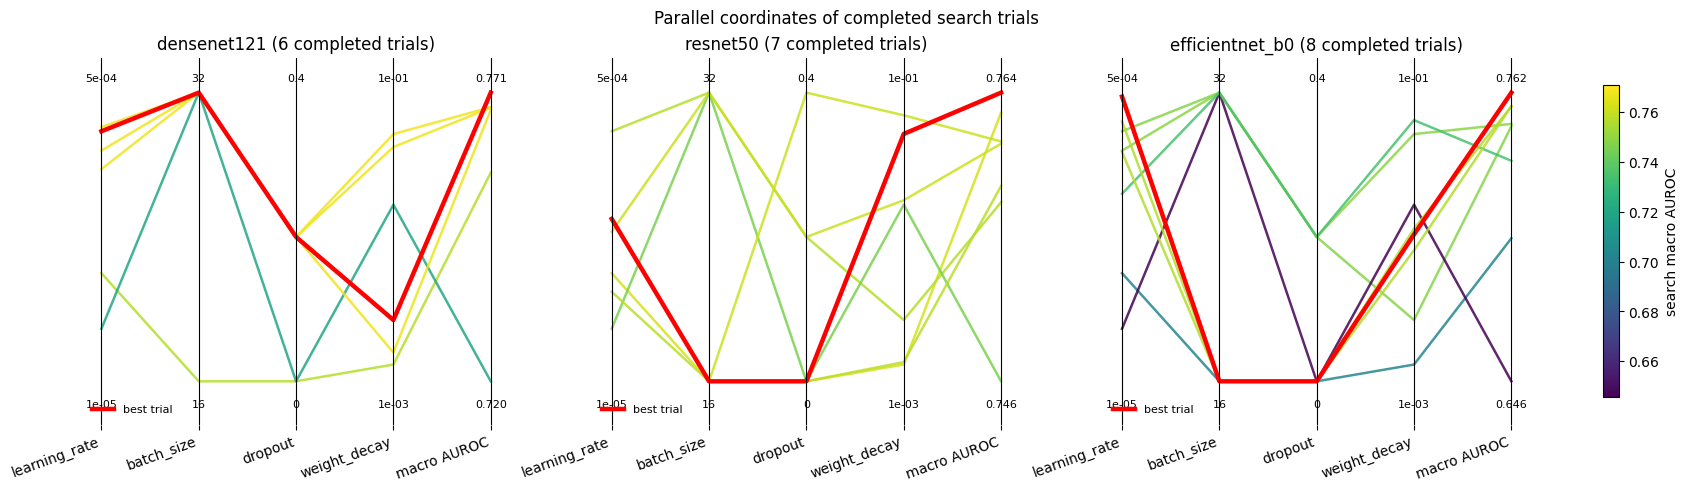

In [17]:
# [Cell 14b] Parallel coordinate chart per backbone
def norm_param(name, values):
    lo, hi = SEARCH_BOUNDS[name]
    v = np.asarray(values, dtype=float)
    if name in LOG_PARAMS:
        return (np.log10(v) - np.log10(lo)) / (np.log10(hi) - np.log10(lo))
    return (v - lo) / (hi - lo)


def fmt_bound(name, v):
    return f"{v:.0e}" if name in LOG_PARAMS else f"{v:g}"


done = trials[trials["state"] == "COMPLETE"]
vmin, vmax = done["value"].min(), done["value"].max()
cmap = plt.get_cmap("viridis")
axis_labels = PARAMS + ["macro AUROC"]
xs = np.arange(len(axis_labels))

fig, axes = plt.subplots(1, len(BACKBONES), figsize=(5.6 * len(BACKBONES), 4.8),
                         sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)
for ax, b in zip(axes, BACKBONES):
    d = done[done["backbone"] == b]
    ax.set_title(f"{b} ({len(d)} completed trials)")
    if d.empty:
        continue
    values = d["value"].to_numpy()
    span = max(values.max() - values.min(), 1e-12)
    ys = np.column_stack([norm_param(p, d[f"params_{p}"]) for p in PARAMS] + [(values - values.min()) / span])
    for row, val in zip(ys, values):
        ax.plot(xs, row, color=cmap((val - vmin) / max(vmax - vmin, 1e-12)), alpha=0.85, lw=1.8)
    ax.plot(xs, ys[values.argmax()], color="red", lw=3.2, label="best trial")
    for x in xs:
        ax.axvline(x, color="k", lw=0.8)
    for x, p in zip(xs[:-1], PARAMS):
        lo, hi = SEARCH_BOUNDS[p]
        ax.text(x, 1.04, fmt_bound(p, hi), ha="center", fontsize=8)
        ax.text(x, -0.09, fmt_bound(p, lo), ha="center", fontsize=8)
    ax.text(xs[-1], 1.04, f"{values.max():.3f}", ha="center", fontsize=8)
    ax.text(xs[-1], -0.09, f"{values.min():.3f}", ha="center", fontsize=8)
    ax.set_xticks(xs)
    ax.set_xticklabels(axis_labels, rotation=20, ha="right")
    ax.set_yticks([])
    ax.set_ylim(-0.15, 1.12)
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="lower left", fontsize=8, frameon=False)

sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin, vmax), cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=list(axes), label="search macro AUROC", shrink=0.85)
fig.suptitle("Parallel coordinates of completed search trials")
fig.savefig(FIG_DIR / "parallel_coordinates.png", dpi=200, bbox_inches="tight")
plt.show()

densenet121: fANOVA from 6 completed trials (indicative only, fewer than 15 completed trials)
resnet50: fANOVA from 7 completed trials (indicative only, fewer than 15 completed trials)
efficientnet_b0: fANOVA from 8 completed trials (indicative only, fewer than 15 completed trials)


,densenet121,resnet50,efficientnet_b0
learning_rate,0.421,0.624,0.747
batch_size,0.165,0.111,0.087
dropout,0.308,0.107,0.021
weight_decay,0.106,0.158,0.146


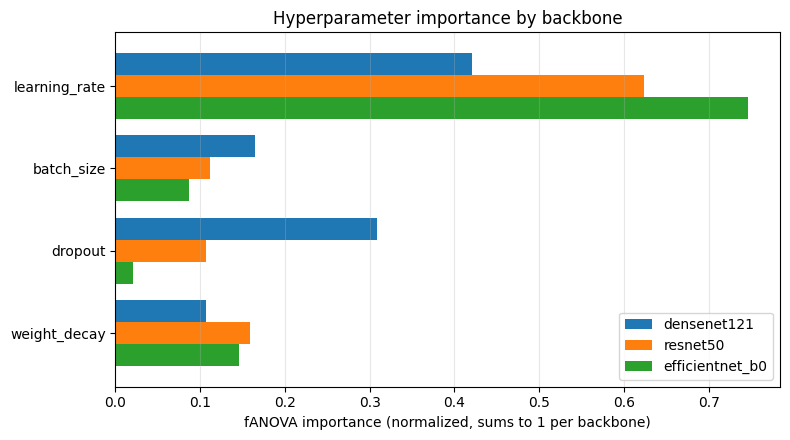

In [18]:
# [Cell 14c] fANOVA importance
from optuna.importance import FanovaImportanceEvaluator, get_param_importances

importances = {}
for b, s in search_studies.items():
    n_done = sum(t.state == optuna.trial.TrialState.COMPLETE for t in s.trials)
    try:
        importances[b] = get_param_importances(s, evaluator=FanovaImportanceEvaluator(seed=SEED), params=PARAMS)
        note = " (indicative only, fewer than 15 completed trials)" if n_done < 15 else ""
        print(f"{b}: fANOVA from {n_done} completed trials{note}")
    except Exception as e:
        print(f"{b}: fANOVA failed with {n_done} completed trials ({type(e).__name__}: {e})")

if importances:
    importance_df = pd.DataFrame(importances).reindex(PARAMS)
    display(importance_df.style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))
    importance_df.to_csv(TABLE_DIR / "fanova_importance.csv")

    ax = importance_df.plot.barh(figsize=(8, 4.5), width=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("fANOVA importance (normalized, sums to 1 per backbone)")
    ax.set_title("Hyperparameter importance by backbone")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fanova_importance.png", dpi=200, bbox_inches="tight")
    plt.show()

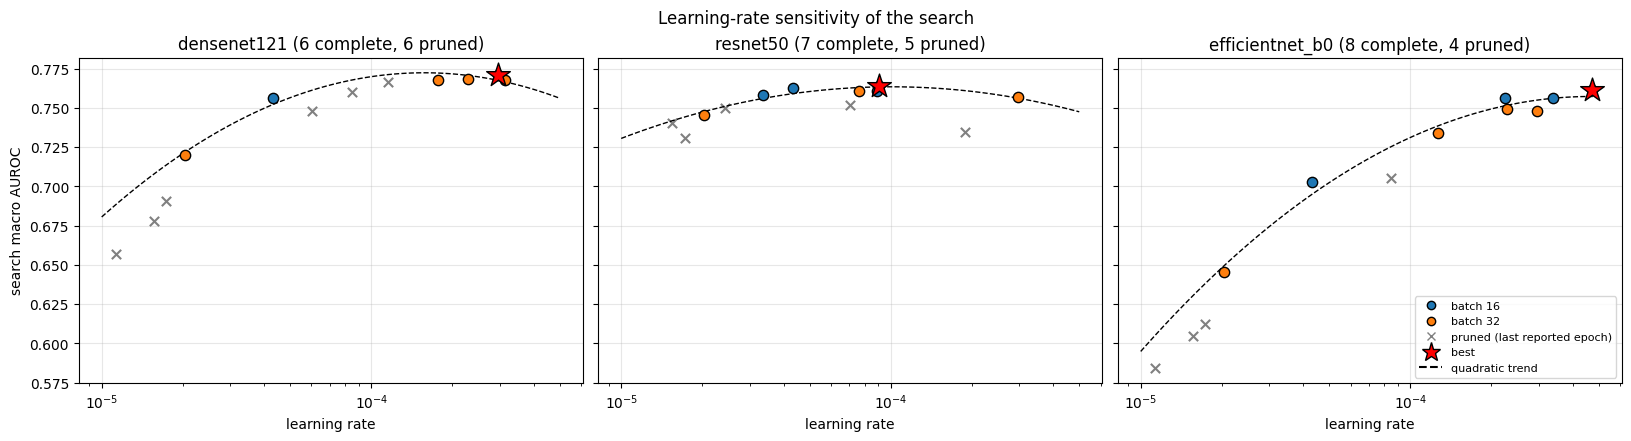

In [19]:
# [Cell 14d] Learning-rate sensitivity curves
from matplotlib.lines import Line2D

bs_color = {16: "tab:blue", 32: "tab:orange"}
fig, axes = plt.subplots(1, len(BACKBONES), figsize=(5.4 * len(BACKBONES), 4.3),
                         sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)

for ax, b in zip(axes, BACKBONES):
    s = search_studies[b]
    comp = [t for t in s.trials if t.state == optuna.trial.TrialState.COMPLETE]
    pruned = [t for t in s.trials if t.state == optuna.trial.TrialState.PRUNED and t.intermediate_values]

    for t in comp:
        ax.scatter(t.params["learning_rate"], t.value, s=55, edgecolor="k", zorder=3,
                   c=bs_color.get(t.params["batch_size"], "gray"))
    if pruned:
        ax.scatter([t.params["learning_rate"] for t in pruned],
                   [t.intermediate_values[max(t.intermediate_values)] for t in pruned],
                   marker="x", c="gray", s=45, zorder=2)
    if len(comp) >= 6:   # quadratic trend in log10(lr); only a rough guide
        x = np.log10([t.params["learning_rate"] for t in comp])
        y = np.array([t.value for t in comp])
        grid = np.linspace(np.log10(SEARCH_BOUNDS["learning_rate"][0]), np.log10(SEARCH_BOUNDS["learning_rate"][1]), 100)
        ax.plot(10 ** grid, np.polyval(np.polyfit(x, y, 2), grid), "--", color="k", lw=1)

    best = s.best_trial
    ax.scatter(best.params["learning_rate"], best.value, marker="*", s=320, c="red", edgecolor="k", zorder=4)
    ax.set_xscale("log")
    ax.set_xlabel("learning rate")
    ax.set_title(f"{b} ({len(comp)} complete, {len(pruned)} pruned)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("search macro AUROC")
handles = [Line2D([], [], marker="o", ls="", mfc="tab:blue", mec="k", label="batch 16"),
           Line2D([], [], marker="o", ls="", mfc="tab:orange", mec="k", label="batch 32"),
           Line2D([], [], marker="x", ls="", color="gray", label="pruned (last reported epoch)"),
           Line2D([], [], marker="*", ls="", mfc="red", mec="k", ms=14, label="best"),
           Line2D([], [], ls="--", color="k", label="quadratic trend")]
axes[-1].legend(handles=handles, fontsize=8, loc="lower right")
fig.suptitle("Learning-rate sensitivity of the search")
fig.savefig(FIG_DIR / "lr_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
import shutil

# Save the exact split membership so you can verify the test set is identical in later sessions
pd.concat(
    [d[["patient_id", "shard_path", "shard_index"]].assign(set=name)
     for name, d in {"train": train_data, "tune": val_tune,
                     "test": val_final, "official": val_official}.items()]
).to_csv(OUTPUT_DIR / "split_assignment.csv.gz", index=False)

zip_path = shutil.make_archive("/kaggle/working/chexpert_tuning_checkpoint", "zip",
                               root_dir=OUTPUT_DIR.parent, base_dir=OUTPUT_DIR.name)
n_files = sum(1 for p in OUTPUT_DIR.rglob("*") if p.is_file())
print(f"{zip_path}: {Path(zip_path).stat().st_size / 1e6:.0f} MB, {n_files} files")

/kaggle/working/chexpert_tuning_checkpoint.zip: 130 MB, 28 files
